# Matplotlib_Data_Visualization_Project
This project demonstrates multiple visualization techniques using Matplotlib on the `amazon.csv` dataset, replicating the techniques shown in the reference PDF with custom font styles and sizes applied globally.

The visualizations include:
1. Time Series with Rolling Average, Trend Line, and Annotations (Simulated for demonstration)
2. Violin Plots (Discount Percentage & Rating by Category)
3. Scatter Plot with Regression Lines (Actual vs. Discounted Price)
4. Histogram + Smoothed Density (Ratings)
5. Boxplot + Jittered Points (Discount Percentage by Category)
6. 2D Density via Hexbin (Actual vs Discounted Price)
7. Radar Chart of Feature Means per Category


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
import os

# Set Global Font Style and Size
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans', 'Liberation Sans'],
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 16,
    'axes.titleweight': 'bold'
})

# Load and clean dataset
df = pd.read_csv('amazon.csv')

# Clean numeric columns
df['discounted_price'] = df['discounted_price'].str.replace('₹', '').str.replace(',', '').astype(float)
df['actual_price'] = df['actual_price'].str.replace('₹', '').str.replace(',', '').astype(float)
df['discount_percentage'] = df['discount_percentage'].str.replace('%', '').astype(float)
df['rating_count'] = df['rating_count'].str.replace(',', '').astype(float)

# Clean rating column (drop non-numeric like '|')
df['rating'] = pd.to_numeric(df['rating'], errors='coerce')
df = df.dropna(subset=['rating', 'rating_count', 'discounted_price', 'actual_price'])

# Extract main category
df['main_category'] = df['category'].apply(lambda x: x.split('|')[0])
top_categories = df['main_category'].value_counts().nlargest(3).index
df_top = df[df['main_category'].isin(top_categories)].copy()

out_dir = "amazon_outputs"
os.makedirs(out_dir, exist_ok=True)

def save_and_display(fig, name):
    path = os.path.join(out_dir, name)
    fig.savefig(path, bbox_inches='tight')
    plt.show()


### 1. Visualization 1: Time Series with Trend, Rolling Average, and Annotations
Shows a synthetic daily sales sequence for 180 days, mimicking product demand trends.
* **Blue**: Raw values
* **Orange**: 7-day rolling average (smoother short-term trend)
* **Dashed line**: Overall linear trend (fitted)
* **Annotations**: Highlight the maximum and most recent data points


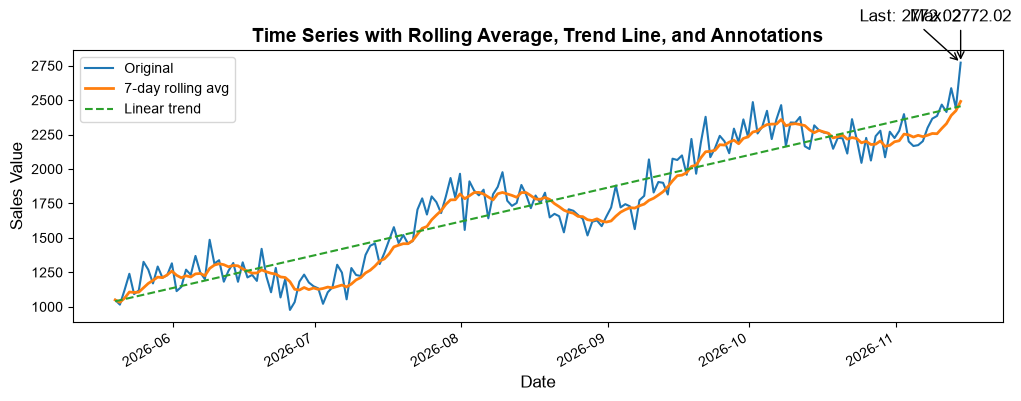

In [2]:
# 1. Time Series with Rolling Average, Trend Line, and Annotations
np.random.seed(42)
days = pd.date_range(end=pd.Timestamp.today(), periods=180)
trend = np.linspace(1000, 2500, len(days))
seasonal = 200 * np.sin(np.linspace(0, 6 * np.pi, len(days)))
noise = np.random.normal(scale=100.0, size=len(days))
values = trend + seasonal + noise
df_ts = pd.DataFrame({'date': days, 'value': values})

df_ts['rolling_7'] = df_ts['value'].rolling(window=7, min_periods=1).mean()
x = np.arange(len(df_ts))
coeffs = np.polyfit(x, df_ts['value'], deg=1)
trend_line = np.polyval(coeffs, x)

fig = plt.figure(figsize=(12, 4))
plt.plot(df_ts['date'], df_ts['value'], label='Original')
plt.plot(df_ts['date'], df_ts['rolling_7'], label='7-day rolling avg', linewidth=2)
plt.plot(df_ts['date'], trend_line, label='Linear trend', linestyle='--')

plt.title('Time Series with Rolling Average, Trend Line, and Annotations')
plt.xlabel('Date'); plt.ylabel('Sales Value')
plt.gcf().autofmt_xdate()

max_idx = df_ts['value'].idxmax()
max_date, max_val = df_ts.loc[max_idx, ['date', 'value']]
plt.annotate(f'Max: {max_val:.2f}', xy=(max_date, max_val),
             xytext=(max_date, max_val + 300),
             arrowprops=dict(arrowstyle='->'), ha='center')

last_date, last_val = df_ts.iloc[-1][['date', 'value']]
plt.annotate(f'Last: {last_val:.2f}', xy=(last_date, last_val),
             xytext=(last_date, last_val + 300),
             arrowprops=dict(arrowstyle='->'), ha='right')

plt.legend()
save_and_display(fig, "01_timeseries_enhanced.png")


### 2. Visualization 2: Violin Plot (Discount Percentage)
**Violin Plot: Discount Percentage by Category:**
Displays the full distribution of discount percentages for each of the top product categories. 
* The width of the violin shows density (probability) of measurements.
* It reveals the overall range, median, and concentration of discounts offered.


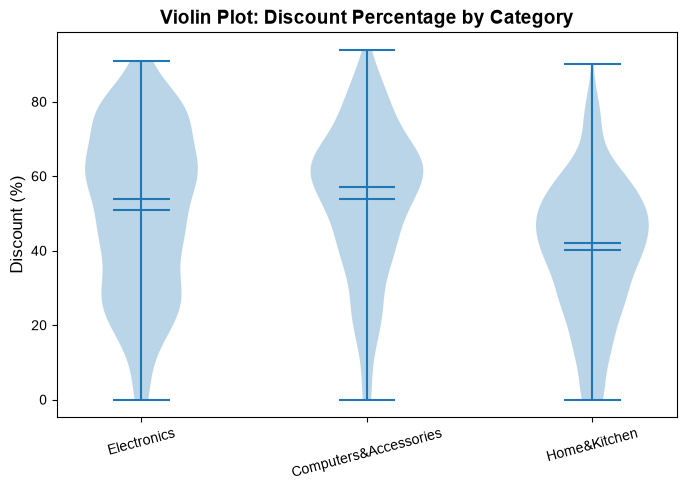

In [3]:
# 2. Violin Plot (Discount Percentage)
groups = [df_top[df_top['main_category'] == cat]['discount_percentage'].values for cat in top_categories]

fig = plt.figure(figsize=(8, 5))
plt.violinplot(groups, showmeans=True, showmedians=True)
plt.xticks(range(1, len(top_categories) + 1), top_categories, rotation=15)
plt.title('Violin Plot: Discount Percentage by Category')
plt.ylabel('Discount (%)')
save_and_display(fig, "02_violin_discount.png")


### 3. Visualization 3: Violin Plot (Rating)
**Violin Plot: Rating by Category:**
Similar to the previous plot but for customer ratings.
* It reveals subtle differences in shape and spread among the top categories.


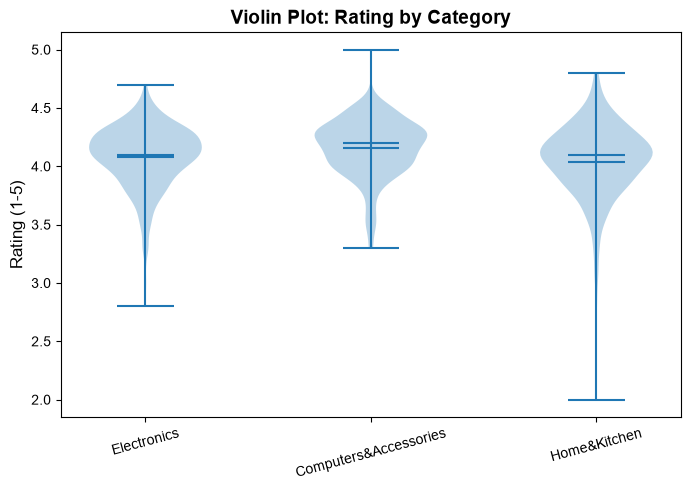

In [4]:
# 3. Violin Plot (Rating)
groups_rating = [df_top[df_top['main_category'] == cat]['rating'].values for cat in top_categories]

fig = plt.figure(figsize=(8, 5))
plt.violinplot(groups_rating, showmeans=True, showmedians=True)
plt.xticks(range(1, len(top_categories) + 1), top_categories, rotation=15)
plt.title('Violin Plot: Rating by Category')
plt.ylabel('Rating (1-5)')
save_and_display(fig, "03_violin_rating.png")


### 4. Visualization 4: Scatter Plot with Regression Lines
**Scatter Plot with Per-Category Trend Lines:**
* Plots Actual Price vs. Discounted Price for each category.
* A separate linear regression trend line (dashed) is fitted per category, illustrating relationships and slope variations between original pricing and the final discounted price.


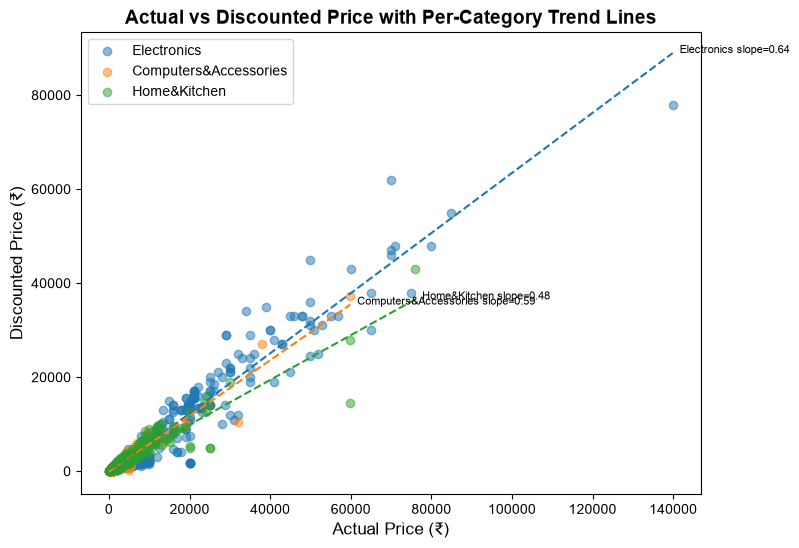

In [5]:
# 4. Scatter Plot with Regression Lines (Actual vs Discounted Price)
fig = plt.figure(figsize=(8, 6))

for cat in top_categories:
    subset = df_top[df_top['main_category'] == cat]
    x, y = subset['actual_price'], subset['discounted_price']
    plt.scatter(x, y, label=cat, alpha=0.5)
    
    if len(x) > 1:
        m, b = np.polyfit(x, y, 1)
        xs = np.linspace(x.min(), x.max(), 100)
        plt.plot(xs, m * xs + b, linestyle='--')
        
        plt.annotate(f'{cat} slope={m:.2f}', xy=(xs.iloc[-1] if isinstance(xs, pd.Series) else xs[-1], 
                     m * (xs.iloc[-1] if isinstance(xs, pd.Series) else xs[-1]) + b),
                     xytext=(5, 0), textcoords='offset points', fontsize=8)

plt.title('Actual vs Discounted Price with Per-Category Trend Lines')
plt.xlabel('Actual Price (₹)')
plt.ylabel('Discounted Price (₹)')
plt.legend()
save_and_display(fig, "04_scatter_trendlines.png")


### 5. Visualization 5: Histogram + Smoothed Density
**Histogram with Smoothed Density (KDE Approximation):**
* Histogram of customer ratings with a smoothed curve (approximate kernel density) overlaid using Gaussian filtering.
* This reveals both discrete bin counts and continuous distribution shape.


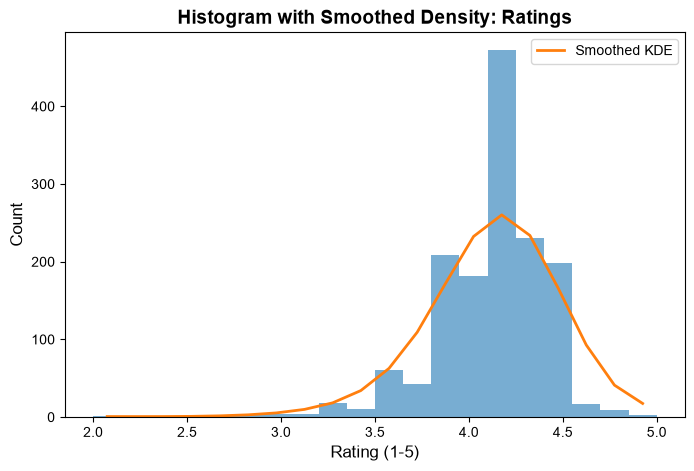

In [6]:
# 5. Histogram + Smoothed Density (Ratings)
fig = plt.figure(figsize=(8, 5))
data = df['rating'].values

counts, bins, _ = plt.hist(data, bins=20, alpha=0.6)
bin_centers = (bins[:-1] + bins[1:]) / 2

smooth = gaussian_filter1d(counts.astype(float), sigma=1.5)
plt.plot(bin_centers, smooth, linewidth=2, label='Smoothed KDE')

plt.title('Histogram with Smoothed Density: Ratings')
plt.xlabel('Rating (1-5)')
plt.ylabel('Count')
plt.legend()
save_and_display(fig, "05_hist_kde_rating.png")


### 6. Visualization 6: Boxplot + Jittered Points
**Boxplot + Jittered Scatter: Discount Percentage by Category:**
* Combines statistical summary (boxplot) and raw data visibility (jittered dots).
* Each box shows median, quartiles, and whiskers.
* Jittered points prevent overlap and reveal the distribution spread and density for each category.


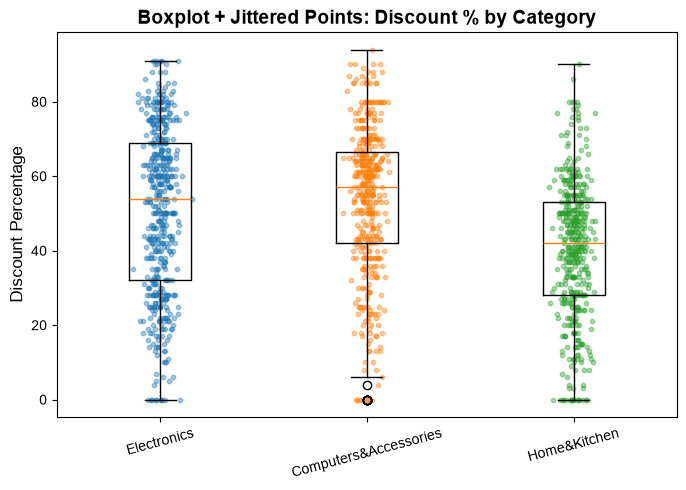

In [7]:
# 6. Boxplot + Jittered Scatter (Discount Percentage)
fig = plt.figure(figsize=(8, 5))
data_to_plot = [df_top[df_top['main_category'] == cat]['discount_percentage'].values for cat in top_categories]

plt.boxplot(data_to_plot, tick_labels=top_categories)

for i, cat in enumerate(top_categories, start=1):
    vals = df_top[df_top['main_category'] == cat]['discount_percentage'].values
    x_jitter = np.random.normal(loc=i, scale=0.04, size=len(vals))
    plt.scatter(x_jitter, vals, alpha=0.4, s=10)

plt.title('Boxplot + Jittered Points: Discount % by Category')
plt.ylabel('Discount Percentage')
plt.xticks(rotation=15)
save_and_display(fig, "06_boxplot_jitter.png")


### 7. Visualization 7: 2D density via hexbin (Actual vs Discounted Price)
When you have a large number of 2D data points (like a scatter plot) that overlap a lot, a hexbin plot groups nearby points into hexagonal bins and colors them by how many points fall inside each bin.
* It's a 2D histogram using hexagons instead of rectangles.
* **Use cases**: Visualizing correlation density between two continuous variables (e.g., Actual Price vs Discounted Price). When scatter plots are too dense or slow to render, Hexbin reduces overplotting and highlights dense regions.


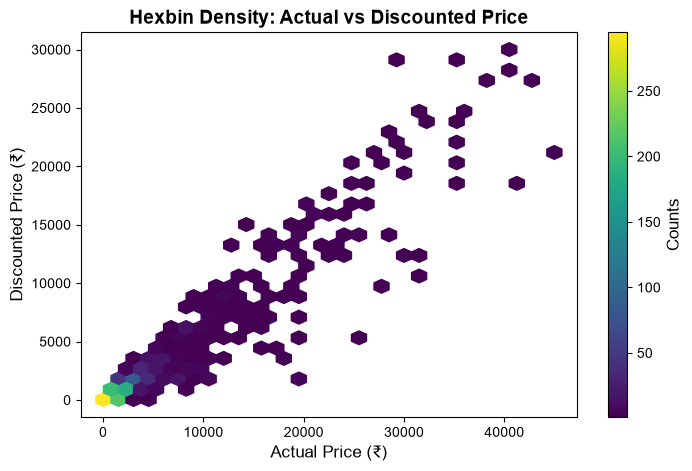

In [8]:
# 7. Hexbin Density (Actual vs Discounted Price)
fig = plt.figure(figsize=(8, 5))
hex_df = df[(df['actual_price'] < 50000) & (df['discounted_price'] < 30000)]

plt.hexbin(hex_df['actual_price'], hex_df['discounted_price'], gridsize=30, cmap='viridis', mincnt=1)
plt.colorbar(label='Counts')
plt.title('Hexbin Density: Actual vs Discounted Price')
plt.xlabel('Actual Price (₹)')
plt.ylabel('Discounted Price (₹)')
save_and_display(fig, "07_hexbin_density.png")


### 8. Visualization 8: Radar (spider) chart of feature means per category
Compares multivariate profiles by plotting normalized mean features (prices, discounts, ratings) for each category on a polar axis.
* A radar chart is used to compare multidimensional feature profiles across multiple categories.
* Each variable (feature) has its own axis radiating out from the center (like spokes on a wheel).
* Each category forms a closed polygon connecting the values for its features.


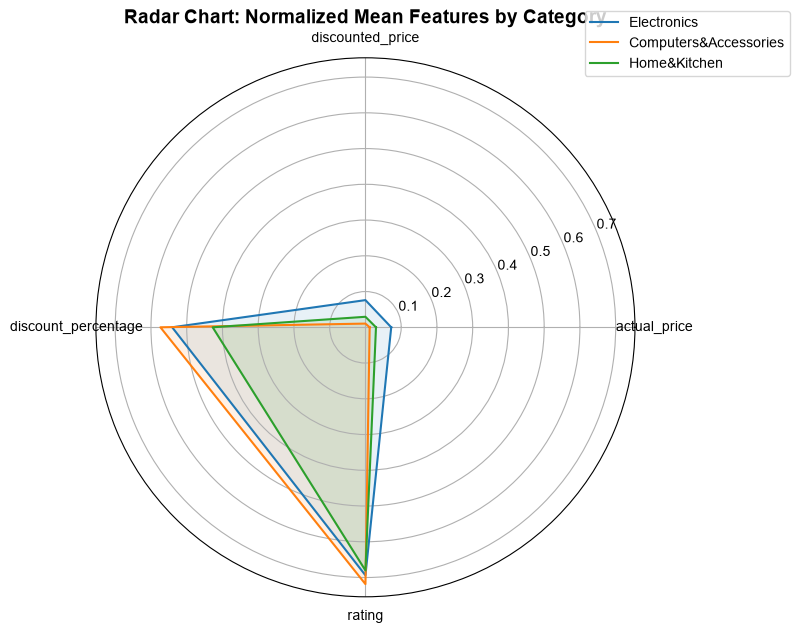

In [9]:
# 8. Radar Chart of Feature Means
features = ['actual_price', 'discounted_price', 'discount_percentage', 'rating']

df_norm = df_top.copy()
for f in features:
    df_norm[f] = (df_norm[f] - df_norm[f].min()) / (df_norm[f].max() - df_norm[f].min())

angles = np.linspace(0, 2 * np.pi, len(features), endpoint=False)
angles = np.concatenate([angles, angles[:1]]) 

fig = plt.figure(figsize=(7, 7))
ax = plt.subplot(111, polar=True)

for cat in top_categories:
    means = df_norm.loc[df_norm['main_category'] == cat, features].mean().values
    vals = np.concatenate([means, means[:1]])
    ax.plot(angles, vals, label=cat)
    ax.fill(angles, vals, alpha=0.1)

ax.set_thetagrids(angles[:-1] * 180 / np.pi, features)
plt.title('Radar Chart: Normalized Mean Features by Category')
plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
save_and_display(fig, "08_radar_means.png")
